# Notebook 1. Where to find precipitation observations

**Predicting Flash Floods in Working Landscapes**, Module 1, Quantitative Precipitation Estimation (QPE)
CUAHSI Water Science Exchange 2026, University of Missouri, Saturday November 14, 2026
Mohamed Abdelkader, Humberto Vergara and Santiago Henao Gomez, University of Iowa, IIHR and Iowa Flood Center

## Learning objectives of Module 1

By the end of this module you will be able to

1. Describe the main sources of precipitation estimates (rain gauge networks, weather radar, satellites, model analyses) and the multi-sensor products built from them.
2. Access near real time precipitation products and gauge observations from public archives with Python, clip them to a region of interest, and compare them on a map.
3. Explain the trade-off between latency and accuracy in operational QPE, and measure it directly in the archives.
4. Evaluate radar-only and gauge-corrected rainfall estimates against independent gauges for a flash flood event.

Objectives 1 to 3 are covered in this notebook. Objective 4 is the subject of Notebook 2.

## What this notebook does

This is a guided tour of the places where precipitation data live. We stay in the Upper Midwest and we use one hour of the storm that we study in depth in Notebook 2, the night of June 21 to 22, 2024, in northwest Iowa.

| Section | Source | What we practice |
|---|---|---|
| 1 | The map of sources | Names, resolutions, latencies |
| 2 | MRMS on Amazon Web Services | Download, decode GRIB2, clip, map |
| 3 | MRMS at Iowa State University | A second copy of the same files |
| 4 | Latency measured in the archive | Radar only vs Pass 1 vs Pass 2 |
| 5 | NCEP Stage IV | A second multi-sensor analysis on another grid |
| 6 | Rain gauge networks | Find stations, pull hourly and daily records |
| 7 | GOES satellite rainfall | Rain rate from space |
| 8 | Guided activity | Your turn |

How to run. Click a cell and press Shift + Enter. Run the cells from top to bottom.

## 0. Setup

Run the next cell first. In Google Colab it copies this module to the cloud machine and installs the two libraries Colab lacks (about one minute). On your own computer, with the notebook opened from the repository folder, it only checks that the packages are there.

In [1]:
import os, sys, subprocess, importlib.util
from pathlib import Path

REPO_URL = "https://github.com/AHWALab/Water-Science-Exchange-Workshop.git"
BRANCH = "module-1-qpe"

# Step 1. If the helper file is not next to this notebook, we are in Colab. Copy the branch (public, no account needed).
if not Path("qpe_tools.py").exists():
    if not Path("Water-Science-Exchange-Workshop").is_dir():
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "-b", BRANCH, REPO_URL, "Water-Science-Exchange-Workshop"], check=True)
    os.chdir("Water-Science-Exchange-Workshop/notebooks")
sys.path.insert(0, os.getcwd())

# Step 2. Install what is missing. Colab lacks the GRIB2 reader and the map library. About one minute the first time.
missing = [m for m in ["eccodes", "cfgrib", "cartopy", "s3fs", "h5netcdf"] if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
print("Working folder:", os.getcwd(), "| installed:", ", ".join(missing) if missing else "nothing, all packages present")

Working folder: /home/claude/wse/notebooks | installed: nothing, all packages present


In [2]:
import warnings; warnings.filterwarnings("ignore")      # hide library warnings, not errors
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from qpe_tools import *            # the helper functions of this module (open qpe_tools.py to read them)

plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "text.color": "black",
                     "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"})

# Our region. West, east, south, north, in degrees.
MIDWEST = (-98.0, -90.0, 40.0, 45.0)

# The hour we look at everywhere in this notebook. MRMS files are stamped with the END of the hour.
WHEN = "2024-06-22 04:00"          # UTC, that is 11 pm Central Daylight Time on June 21

print("Ready. Region", MIDWEST, "Hour ending", WHEN, "UTC")

Ready. Region (-98.0, -90.0, 40.0, 45.0) Hour ending 2024-06-22 04:00 UTC


## 1. The map of sources

Precipitation can be measured at a point (gauges) or estimated remotely (radar, satellite). Operational products combine several of these. The table lists what we use today. Latency means how long after the hour the data become available.

| Source | What it is | Grid or network | Latency | Read it with |
|---|---|---|---|---|
| MRMS Radar only | Radar rainfall from about 180 radars, no gauges | 1 km, every 2 min, hourly totals | Minutes | AWS bucket `noaa-mrms-pds` |
| MRMS Multi-sensor Pass 1 | Radar corrected with the gauges received early | 1 km, hourly | About 20 min | AWS |
| MRMS Multi-sensor Pass 2 | Same, with more gauges | 1 km, hourly | About 1 h | AWS, Iowa State mirror |
| NCEP Stage IV | Radar plus gauges, quality controlled by River Forecast Centers | 4 km HRAP grid, hourly, 6 h, 24 h | About 1 h, revised for 7 days | Iowa Environmental Mesonet archive |
| ASOS and AWOS | Airport weather stations, heated tipping bucket or weighing gauge | About 950 ASOS sites in the US | Minutes | IEM web service |
| ISU Soil Moisture Network | Iowa mesonet, tipping bucket | About 30 sites in Iowa | Minutes to 1 h | IEM web service |
| USCRN | NOAA climate reference network, weighing gauge with three sensors | 114 sites in the lower 48 | About 1 h | NCEI text files |
| CoCoRaHS | Volunteer 4 inch manual gauges | Over 20,000 observers | Next morning | IEM web service |
| GOES RRQPE (SCaMPR) | Rain rate from the GOES satellite infrared and water vapour channels | 2 km at nadir, every 10 min | Minutes | AWS bucket `noaa-goes16` |

Sources for the numbers are listed in `docs/qpe_data_catalog.md`.

## 2. MRMS on Amazon Web Services

NOAA copies every MRMS product to a public bucket. No account is needed. The layout is

```
noaa-mrms-pds / CONUS / <PRODUCT> / <YYYYMMDD> / MRMS_<PRODUCT>_<YYYYMMDD>-<HHMMSS>.grib2.gz
```

Each file is one national grid (3500 rows by 7000 columns, 0.01 degree) compressed with gzip. We do the first download step by step. After that, one helper function does the same work.

In [3]:
# Step 1. Build the link of the file. The helper only glues the pieces together.
url = mrms_url("Pass2", WHEN, source="aws")
print(url)

https://noaa-mrms-pds.s3.amazonaws.com/CONUS/MultiSensor_QPE_01H_Pass2_00.00/20240622/MRMS_MultiSensor_QPE_01H_Pass2_00.00_20240622-040000.grib2.gz


In [4]:
import requests, gzip
import eccodes as ec

# Step 2. Download the compressed file (about 1 MB) and decompress it in memory.
raw = gzip.decompress(requests.get(url, timeout=120).content)

# Step 3. Decode the GRIB2 message with ecCodes.
h = ec.codes_new_from_message(raw)
ncols = ec.codes_get(h, "Ni")                                     # points along a row (longitude)
nrows = ec.codes_get(h, "Nj")                                     # points along a column (latitude)
lat0  = ec.codes_get(h, "latitudeOfFirstGridPointInDegrees")      # north edge
lon0  = ec.codes_get(h, "longitudeOfFirstGridPointInDegrees")     # west edge, in 0 to 360 convention
step  = ec.codes_get(h, "iDirectionIncrementInDegrees")           # 0.01 degree
values = ec.codes_get_values(h).reshape(nrows, ncols)             # the rainfall numbers, mm
ec.codes_release(h)

print("grid", nrows, "rows x", ncols, "columns, first point", lat0, "N", lon0 - 360, "E, step", step)
print("value range", values.min(), "to", values.max(), "mm")

grid 3500 rows x 7000 columns, first point 54.995 N -129.995 E, step 0.01
value range -3.0 to 89.10000000000001 mm


Negative numbers are codes, not rain. In MRMS, -1 means missing and -3 means no radar coverage. We mask them. Then we build the coordinates and clip the national grid to our region.

In [5]:
# Step 4. Coordinates. Rows go north to south, columns west to east.
lat = lat0 - step * np.arange(nrows)
lon = lon0 + step * np.arange(ncols) - 360          # from 230..300 to -130..-60

field = xr.DataArray(np.where(values < 0, np.nan, values), dims=("lat", "lon"),
                     coords={"lat": lat, "lon": lon}, name="Pass2")

# Step 5. Clip. Latitude runs downward, so the slice goes north to south.
west, east, south, north = MIDWEST
midwest = field.sel(lat=slice(north, south), lon=slice(west, east))
print("clipped grid", midwest.shape, "largest hourly total", float(midwest.max()), "mm")

clipped grid (500, 800) largest hourly total 65.9 mm


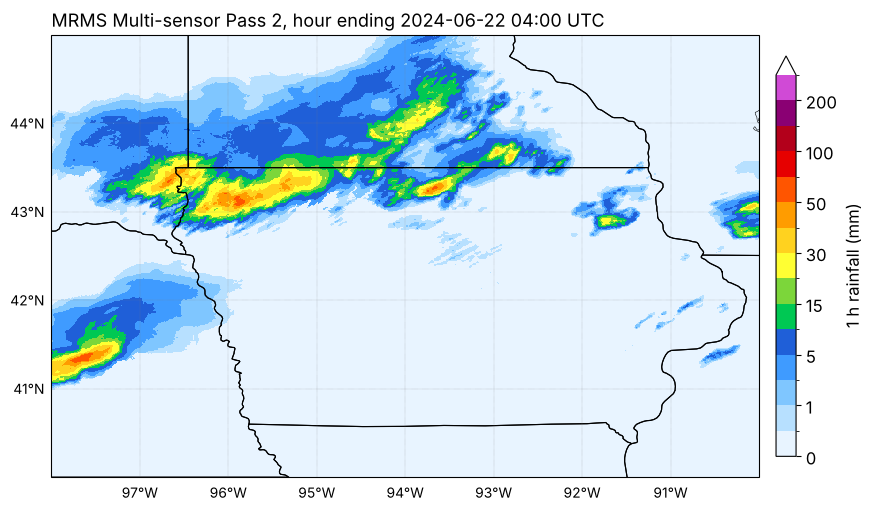

In [6]:
fig = plt.figure(figsize=(11, 6.5))
ax = plt.axes(projection=ccrs.PlateCarree())
mesh = rain_map(midwest, MIDWEST, f"MRMS Multi-sensor Pass 2, hour ending {WHEN} UTC", ax=ax)
fig.colorbar(mesh, ax=ax, shrink=0.8, pad=0.02, label="1 h rainfall (mm)")
plt.show()

The helper `read_mrms(product, time, box)` repeats steps 1 to 5 and keeps a copy of the clipped field in `data/cache`. The second call to the same file is instant, and the notebook also works offline once the cache is filled.

In [7]:
pass2 = read_mrms("Pass2", WHEN, MIDWEST)          # same field, one line
print(pass2.shape, pass2.attrs)

(500, 800) {'valid_time': '2024-06-22T04:00:00+00:00', 'product': 'Pass2', 'source': 'aws', 'units': 'mm', 'long_name': 'Multi-sensor Pass 2'}


## 3. The same files at Iowa State University

Iowa State University keeps a long archive of NCEP products on a plain web server (mtarchive). A normal link works, no S3 tools needed.

```
https://mtarchive.geol.iastate.edu/<YYYY>/<MM>/<DD>/mrms/ncep/<PRODUCT>/...
```

Only a subset of MRMS is mirrored there (PrecipRate, Radar only and Pass 2, for 1 h, 24 h and 72 h). Pass 1 is not. Let us confirm that both copies are identical.

In [8]:
print(mrms_url("Pass2", WHEN, source="iastate"))

pass2_isu = read_mrms("Pass2", WHEN, MIDWEST, source="iastate", refresh=True, save_cache=False)

same = np.allclose(pass2.fillna(-9).values, pass2_isu.fillna(-9).values)
print("AWS and Iowa State give the same numbers:", same)

https://mtarchive.geol.iastate.edu/2024/06/22/mrms/ncep/MultiSensor_QPE_01H_Pass2/MultiSensor_QPE_01H_Pass2_00.00_20240622-040000.grib2.gz


AWS and Iowa State give the same numbers: True


Which one to use

- AWS when you need the newest files, Pass 1, or many files in parallel.
- Iowa State when you want a quick look at a past event with a browser or `wget`.

## 4. Latency measured in the archive

Every object in the AWS bucket records the moment it was uploaded. Upload time minus valid time is the real latency of the product on that day. No documentation needed, the archive tells us.

In [9]:
DAY = "2024-06-22"
latency = pd.concat([mrms_upload_latency(p, DAY) for p in ["RadarOnly", "Pass1", "Pass2"]])

summary = latency.groupby("product").latency_min.describe()[["min", "50%", "max"]].round(1)
summary.columns = ["fastest (min)", "median (min)", "slowest (min)"]
summary.loc[["RadarOnly", "Pass1", "Pass2"]]

,fastest (min),median (min),slowest (min)
product,,,
RadarOnly,2.8,10.7,32.4
Pass1,15.6,17.5,44.6
Pass2,57.6,67.9,90.5


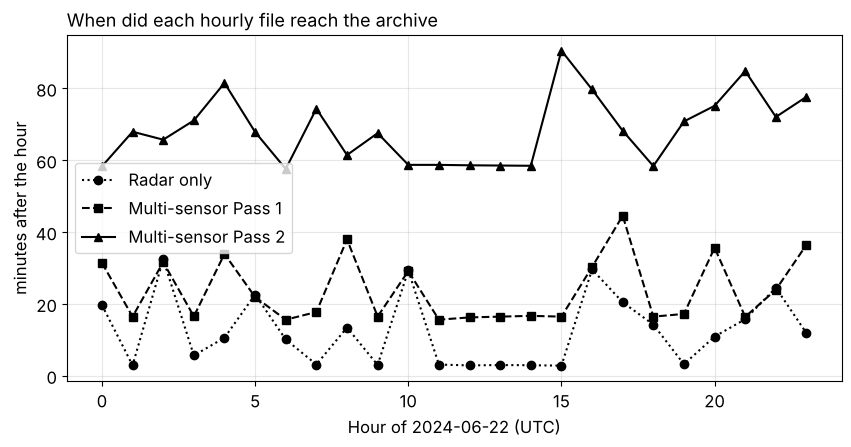

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for p, marker in zip(["RadarOnly", "Pass1", "Pass2"], ["o", "s", "^"]):
    d = latency[latency["product"] == p]
    ax.plot(d.valid_time.dt.hour, d.latency_min, marker=marker, label=LABELS[p], color="black",
            linestyle="-" if p == "Pass2" else "--" if p == "Pass1" else ":")
ax.set_xlabel(f"Hour of {DAY} (UTC)")
ax.set_ylabel("minutes after the hour")
ax.set_title("When did each hourly file reach the archive", loc="left")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Reading the figure

- Radar only files arrive within minutes.
- Pass 1 waits about 20 minutes for the first gauge reports.
- Pass 2 waits about one hour for the rest of the gauges.

Older papers quote 60 and 120 minutes for Pass 1 and Pass 2. The current MRMS version (12.2) lists 20 minutes and 1 hour, and the archive agrees. This is the central trade-off of the day. Faster products see fewer gauges.

## 5. NCEP Stage IV, a second multi-sensor analysis

Stage IV is the national mosaic of the regional analyses made by the twelve River Forecast Centers. Forecasters apply manual quality control, so the product is revised for several days. It lives on the HRAP polar stereographic grid, about 4 km. We read the hourly file from the Iowa Environmental Mesonet archive.

In [11]:
stage4 = read_stage4(WHEN, MIDWEST)
print(stage4.precip.shape, "cells of about 4 km. Largest value", float(np.nanmax(stage4.precip)), "mm")

(156, 175) cells of about 4 km. Largest value 62.625 mm


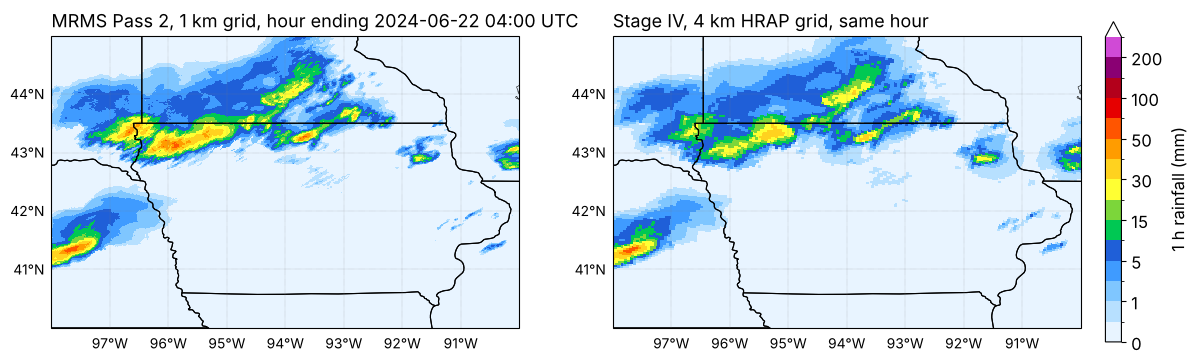

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), subplot_kw={"projection": ccrs.PlateCarree()})
m1 = rain_map(pass2, MIDWEST, f"MRMS Pass 2, 1 km grid, hour ending {WHEN} UTC", ax=axes[0])
m2 = rain_map(stage4.precip, MIDWEST, "Stage IV, 4 km HRAP grid, same hour", ax=axes[1],
              lon=stage4.lon, lat=stage4.lat)
fig.colorbar(m2, ax=axes, shrink=0.8, pad=0.02, label="1 h rainfall (mm)")
plt.show()

Both products see the same storm. Stage IV is smoother because of the coarser grid and because the inputs were already gauge adjusted at the RFC. MRMS keeps the 1 km detail that a flash flood model needs.

## 6. Rain gauge networks

Gauges are the reference for every gridded product, and also its correction. The Iowa Environmental Mesonet (IEM) at Iowa State University collects dozens of networks and serves them through simple web requests. NOAA NCEI serves the Climate Reference Network as text files.

### 6a. Find the stations

One request per network returns the station list with coordinates.

In [13]:
# Airports (ASOS and AWOS) in four states, plus three research grade networks.
asos = pd.concat([iem_stations(n, MIDWEST) for n in ["IA_ASOS", "SD_ASOS", "MN_ASOS", "NE_ASOS"]])
isusm = iem_stations("ISUSM", MIDWEST)              # ISU Soil Moisture Network, tipping buckets
uscrn = iem_stations("USCRN", MIDWEST)              # NOAA Climate Reference Network
cocorahs = iem_stations("IA_COCORAHS", MIDWEST)     # volunteer daily gauges, Iowa only here

print(f"{len(asos)} airports, {len(isusm)} ISUSM, {len(uscrn)} USCRN, {len(cocorahs)} CoCoRaHS sites in the box")
uscrn

124 airports, 27 ISUSM, 5 USCRN, 927 CoCoRaHS sites in the box


,station,name,lon,lat,network,archive_end
0,54902,Des Moines 17 E,-93.2855,41.5562,USCRN,NaN
1,94996,Lincoln 11 SW,-96.8500,40.6900,USCRN,NaN
2,94995,Lincoln 8 ENE,-96.5600,40.8400,USCRN,NaN
3,54903,Necedah 5 WNW,-90.1700,44.0600,USCRN,NaN
4,04990,Sioux Falls 14 NNE,-96.6200,43.7300,USCRN,NaN


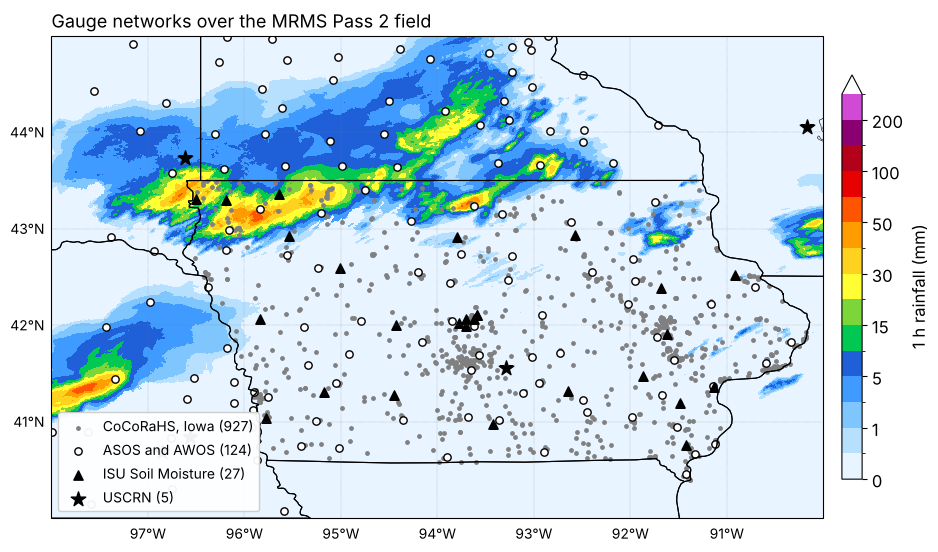

In [14]:
fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
mesh = rain_map(pass2, MIDWEST, "Gauge networks over the MRMS Pass 2 field", ax=ax)
ax.scatter(cocorahs.lon, cocorahs.lat, s=6, color="gray", label=f"CoCoRaHS, Iowa ({len(cocorahs)})", transform=ccrs.PlateCarree())
ax.scatter(asos.lon, asos.lat, s=28, marker="o", facecolor="white", edgecolor="black", label=f"ASOS and AWOS ({len(asos)})", transform=ccrs.PlateCarree())
ax.scatter(isusm.lon, isusm.lat, s=45, marker="^", color="black", label=f"ISU Soil Moisture ({len(isusm)})", transform=ccrs.PlateCarree())
ax.scatter(uscrn.lon, uscrn.lat, s=120, marker="*", color="black", label=f"USCRN ({len(uscrn)})", transform=ccrs.PlateCarree())
ax.legend(loc="lower left", fontsize=10, framealpha=0.95)
fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.02, label="1 h rainfall (mm)")
plt.show()

### 6b. Pull hourly records from three different instruments

We take one station per network near the heavy rain and ask for the 24 hours ending June 22 at 12 UTC.

- ASOS Sioux Falls (FSD). Airport station, heated tipping bucket or weighing gauge.
- ISUSM Doon (DONI4). Agricultural mesonet, tipping bucket, two miles from Rock Valley.
- USCRN Sioux Falls 14 NNE. Weighing gauge with three independent sensors and a wind shield.

Each service has its own format. The helpers return the same three columns, station, valid_time (end of the hour, UTC) and mm.

In [15]:
T0, T1 = "2024-06-21 12:00", "2024-06-22 12:00"

fsd  = iem_asos_hourly(["FSD"], T0, T1)
doon = iem_isusm_hourly(["DONI4"], T0, T1)
crn  = uscrn_hourly("SD_Sioux_Falls_14_NNE", 2024, T0, T1)

for name, df in [("ASOS FSD", fsd), ("ISUSM Doon", doon), ("USCRN Sioux Falls 14 NNE", crn)]:
    print(f"{name:28s} {len(df):2d} hours, total {df.mm.sum():6.1f} mm, max hour {df.mm.max():5.1f} mm")
doon.head()

ASOS FSD                     24 hours, total   52.3 mm, max hour  26.2 mm
ISUSM Doon                   24 hours, total   85.6 mm, max hour  28.2 mm
USCRN Sioux Falls 14 NNE     24 hours, total   55.1 mm, max hour  16.2 mm


,station,valid_time,mm,network
0,DONI4,2024-06-21 13:00:00+00:00,0.000,ISUSM
1,DONI4,2024-06-21 14:00:00+00:00,0.254,ISUSM
2,DONI4,2024-06-21 15:00:00+00:00,0.254,ISUSM
3,DONI4,2024-06-21 16:00:00+00:00,0.000,ISUSM
4,DONI4,2024-06-21 17:00:00+00:00,0.000,ISUSM


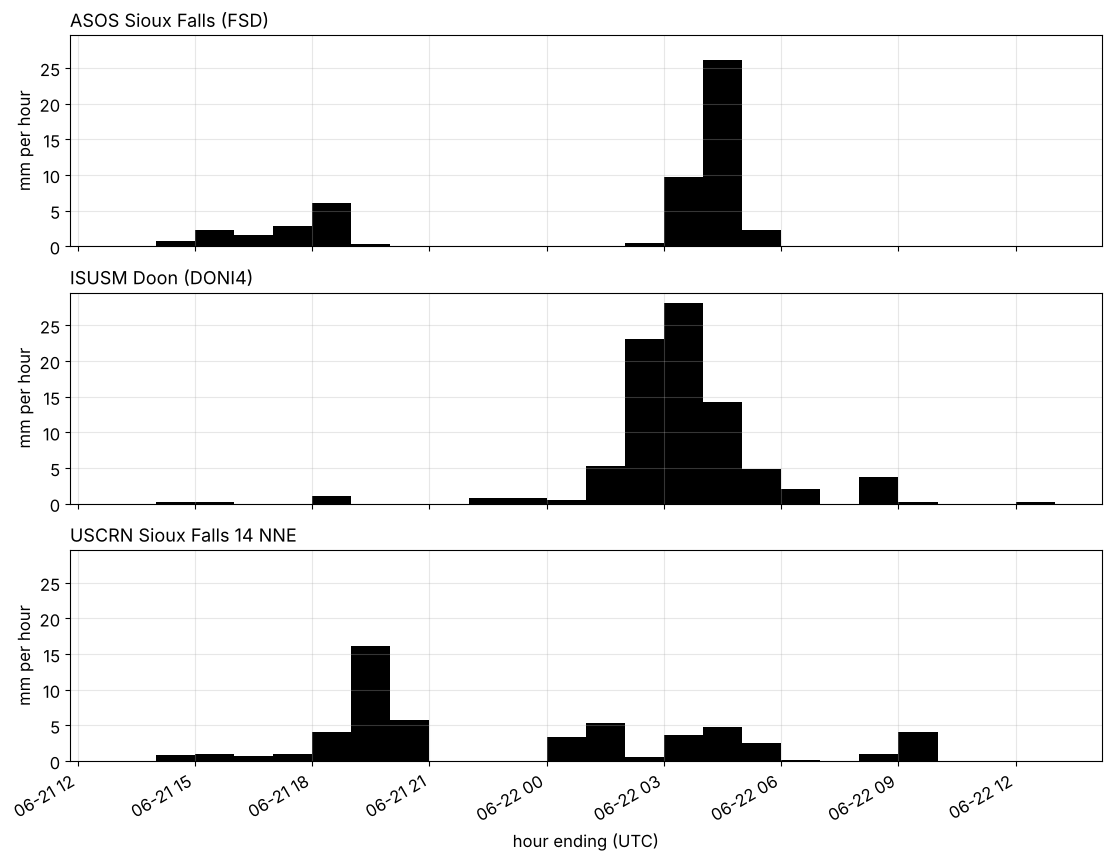

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True, sharey=True, layout="constrained")
for ax, (name, df) in zip(axes, [("ASOS Sioux Falls (FSD)", fsd), ("ISUSM Doon (DONI4)", doon),
                                 ("USCRN Sioux Falls 14 NNE", crn)]):
    ax.bar(df.valid_time, df.mm, width=1 / 24, color="black", align="edge")
    ax.set_title(name, loc="left"); ax.set_ylabel("mm per hour"); ax.grid(alpha=0.3)
axes[-1].set_xlabel("hour ending (UTC)")
fig.autofmt_xdate()
plt.show()

A caution about airports. Many AWOS sites have no precipitation sensor and report zero in every hour. A zero total during a major storm is a missing sensor, not dry weather. Always check a station against its neighbours before trusting it.

### 6c. Daily volunteer reports, CoCoRaHS

CoCoRaHS observers read a 4 inch gauge every morning near 7 am local time, which is 12 UTC in summer in Iowa. The report for June 22 therefore covers roughly the same 24 hours as our window. NSSL uses these reports as independent verification of MRMS because they are not part of the hourly gauge correction.

In [17]:
daily = iem_cocorahs_daily("IA_COCORAHS", "2024-06-22")
print(len(daily), "reports. Largest 24 h totals:")
daily.sort_values("mm", ascending=False)[["station", "name", "mm"]].head(8)

250 reports. Largest 24 h totals:


,station,name,mm
63,IA-DK-15,Milford 1.4 NNE,145.288
65,IA-DK-6,Lake Park 0.2 N,127.254
158,IA-LY-11,Rock Rapids 5.6 W,117.602
159,IA-LY-9,Larchwood 1.2 NNE,113.538
174,IA-PA-5,West Bend 5.4 W,112.014
100,IA-HN-8,Britt 8.2 NNW,108.204
62,IA-DK-12,Milford 1.0 SSE,106.172
64,IA-DK-3,Lake Park 3.2 SSE,90.932


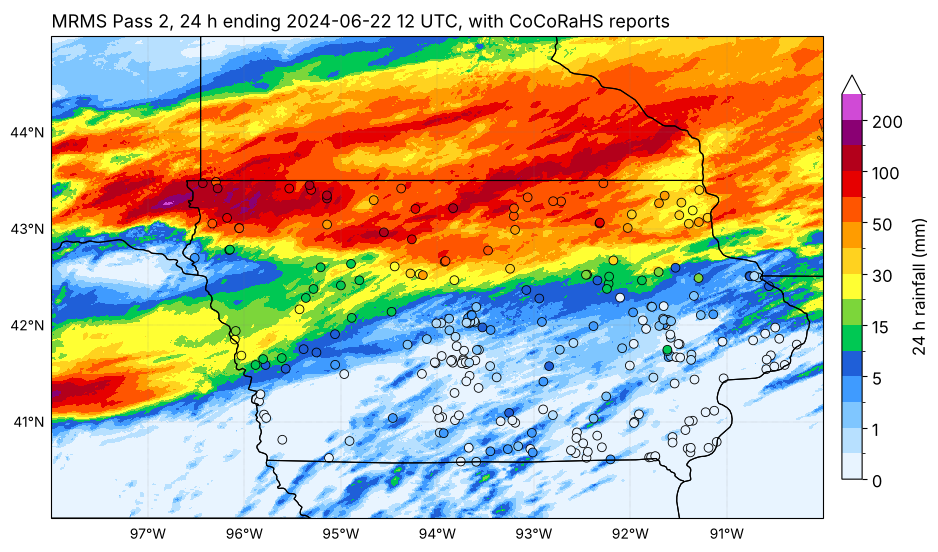

In [18]:
pass2_day = read_mrms("Pass2_24", "2024-06-22 12:00", MIDWEST)      # the official 24 h Pass 2 product

fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
mesh = rain_map(pass2_day, MIDWEST, "MRMS Pass 2, 24 h ending 2024-06-22 12 UTC, with CoCoRaHS reports", ax=ax)
cmap, norm = rain_cmap()
ax.scatter(daily.lon, daily.lat, c=daily.mm, cmap=cmap, norm=norm, s=40, edgecolor="black", linewidth=0.6,
           transform=ccrs.PlateCarree())
fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.02, label="24 h rainfall (mm)")
plt.show()

Dots and background share one colour scale. Where a dot disappears into the background, the product and the gauge agree.

## 7. Rainfall rate from the GOES satellite

Radar beams rise with distance and are blocked by terrain. Satellites see everywhere, all the time, at the price of an indirect estimate. The GOES Rainfall Rate product (RRQPE, from the SCaMPR algorithm) gives a rain rate every 10 minutes at 2 km. We compare one scan with the MRMS 2 minute rain rate at the same time.

In [19]:
goes = read_goes_rrqpe(WHEN, MIDWEST, satellite="goes16")    # GOES-16 was GOES East in 2024
rate = read_mrms("PrecipRate", WHEN, MIDWEST)                 # MRMS instantaneous rate, mm per hour
print("satellite scan started", goes.attrs["scan_start"])

satellite scan started 2024-06-22T04:00:22+00:00


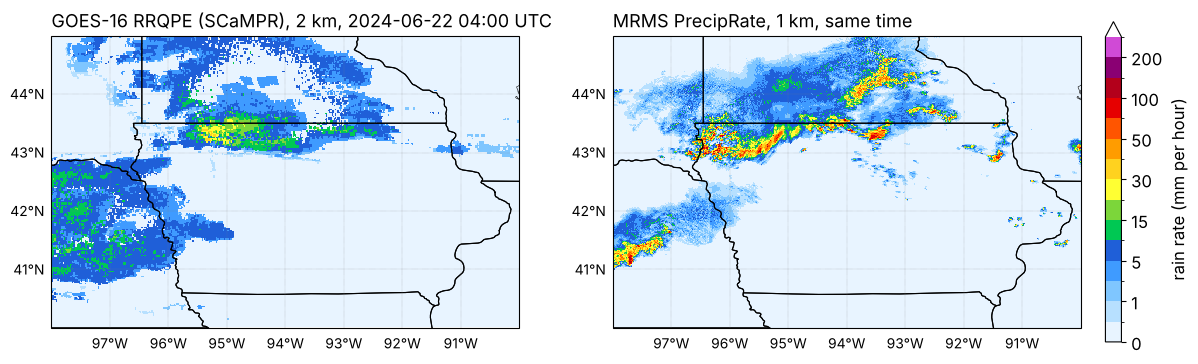

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), subplot_kw={"projection": ccrs.PlateCarree()})
m1 = rain_map(goes, MIDWEST, f"GOES-16 RRQPE (SCaMPR), 2 km, {WHEN} UTC", ax=axes[0])
m2 = rain_map(rate, MIDWEST, "MRMS PrecipRate, 1 km, same time", ax=axes[1])
fig.colorbar(m2, ax=axes, shrink=0.8, pad=0.02, label="rain rate (mm per hour)")
plt.show()

The satellite finds the storm, but the field is smoother and the heaviest cores are displaced or underestimated. This is the typical behaviour of infrared based retrievals, which see cloud tops rather than rain. Satellite products matter most where radar is absent, which is the case for most of the world.

## 8. If the flood is happening now, what do you have

| Minutes after the hour | Available | Not yet available |
|---|---|---|
| 2 to 10 | MRMS radar only, GOES rain rate, ASOS reports | Any gauge corrected grid |
| 20 to 30 | MRMS Pass 1 | Pass 2, Stage IV |
| 60 to 90 | MRMS Pass 2, Stage IV first version, USCRN hourly | CoCoRaHS |
| Next morning | CoCoRaHS daily reports | |
| Days later | Stage IV revisions | |

Flash flood models run with what exists at the time. In Notebook 2 we quantify how much the answer changes while we wait.

## 9. Guided activity

Pick another hour of the storm and another gauge, and check the MRMS product against it.

Suggested choices

- Hours. The storm lasted from the evening of June 20 to the morning of June 22 (UTC dates June 21 and 22).
- Gauges. Any ISUSM station from the list in section 6a, for example Inwood (CSII4), Ocheyedan (SBEI4) or Sutherland (CAMI4). Any ASOS station with a working sensor, for example Spencer (SPW), Worthington (OTG) or Sioux City (SUX).

Fill in the blocks marked `Your Code Goes Here`.

In [21]:
#################### Your Code Goes Here #########################
# Activity, step 1. Choose an hour (UTC, end of the hour) and a station.
MY_HOUR = "2024-06-22 02:00"
MY_STATION = "CSII4"             # ISUSM Inwood

# Activity, step 2. Find the coordinates of the station in the ISUSM station table (isusm, section 6a).
row = isusm[isusm.station == MY_STATION].iloc[0]
my_lon, my_lat = row.lon, row.lat
print(row["name"], my_lon, my_lat)
###################################################################

Inwood - Calico Skies (Vineyard) -96.504251 43.310471


In [22]:
#################### Your Code Goes Here #########################
# Activity, step 3. Read the three MRMS hourly products for MY_HOUR over the Midwest box
#                   and take the value of the grid cell nearest to the station.
values = {}
for product in ["RadarOnly", "Pass1", "Pass2"]:
    field = read_mrms(product, MY_HOUR, MIDWEST)
    values[product] = float(field.sel(lon=my_lon, lat=my_lat, method="nearest"))
values
###################################################################

{'RadarOnly': 43.900001525878906,
 'Pass1': 48.400001525878906,
 'Pass2': 46.900001525878906}

In [23]:
#################### Your Code Goes Here #########################
# Activity, step 4. Pull the gauge value for the same hour (iem_isusm_hourly or iem_asos_hourly)
#                   and compare it with the three products. Which product is closest, and why?
gauge = iem_isusm_hourly([MY_STATION], pd.Timestamp(MY_HOUR) - pd.Timedelta(hours=1), MY_HOUR)
gauge_mm = float(gauge.mm.iloc[-1])
print(f"gauge {MY_STATION}: {gauge_mm:.1f} mm")
for product, v in values.items():
    print(f"{LABELS[product]:22s} {v:6.1f} mm   difference {v - gauge_mm:+6.1f} mm")
###################################################################

gauge CSII4: 60.4 mm
Radar only               43.9 mm   difference  -16.5 mm
Multi-sensor Pass 1      48.4 mm   difference  -12.0 mm
Multi-sensor Pass 2      46.9 mm   difference  -13.5 mm


Questions to discuss with your neighbour

1. Did the gauge correction move the radar estimate toward the gauge, away from it, or not at all? Look at the gauge influence index in Notebook 2 to find out whether this gauge was used.
2. Which of the sources in section 1 would you trust for a flash flood warning at 2 am, and which for a flood report written a week later?

## References and credits

- Project Pythia MRMS Cookbook, Janoski, Sears, Condo, Heaton, Collins and Grover, CC BY 4.0. https://projectpythia.org/mrms-cookbook/
- Zhang, J. and coauthors, 2016. Multi-Radar Multi-Sensor (MRMS) Quantitative Precipitation Estimation, Initial Operating Capabilities. Bulletin of the American Meteorological Society, 97, 621 to 638. https://doi.org/10.1175/BAMS-D-14-00174.1
- NOAA NSSL, MRMS operational product tables, version 12.2. https://nssl.noaa.gov/projects/mrms/operational/tables.php
- NOAA Open Data Dissemination, MRMS on AWS. https://registry.opendata.aws/noaa-mrms-pds/
- Iowa State University, mtarchive. https://mtarchive.geol.iastate.edu/
- Iowa Environmental Mesonet, web services and archive. https://mesonet.agron.iastate.edu/
- NOAA NCEP EMC, Stage IV analysis. https://www.emc.ncep.noaa.gov/mmb/SREF/pcpanl/
- NOAA NCEI, U.S. Climate Reference Network. https://www.ncei.noaa.gov/access/crn/
- NOAA GOES-R, Rainfall Rate (QPE) product. https://www.goes-r.gov/products/baseline-rainfall-rate-qpe.html
- NOAA NESDIS, SCaMPR algorithm. Kuligowski, R. J., 2002, Weather and Forecasting, 17, 705 to 718.